In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product, combinations

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Environment check complete.")

Python: 3.14.2 (main, Aug 25 2026, 05:50:55) [Clang 23.0.0git (https:/github.com/llvm/llvm-project e5927fecf8a6ce89e1a4eac5b8
NumPy: 2.4.6
Pandas: 3.0.2
Environment check complete.


In [2]:
products = pd.DataFrame({
    "product": ["A", "B", "C"],
    "unit_profit": [42, 35, 50],
    "setup_cost": [120, 90, 160],
    "machine_hours": [2.0, 1.5, 3.0],
    "material_units": [3.0, 2.5, 4.0],
    "min_batch": [10, 8, 6],
    "max_units": [100, 120, 80]
})

machine_capacity = 240.0
material_capacity = 360.0

display(products)

print("Machine-hour capacity:", machine_capacity)
print("Material capacity:", material_capacity)

,product,unit_profit,setup_cost,machine_hours,material_units,min_batch,max_units
0,A,42,120,2.0,3.0,10,100
1,B,35,90,1.5,2.5,8,120
2,C,50,160,3.0,4.0,6,80


Machine-hour capacity: 240.0
Material capacity: 360.0


In [3]:
products["profit_per_machine_hour"] = (
    products["unit_profit"] / products["machine_hours"]
)

products["profit_per_material_unit"] = (
    products["unit_profit"] / products["material_units"]
)

display(
    products[
        [
            "product",
            "unit_profit",
            "setup_cost",
            "profit_per_machine_hour",
            "profit_per_material_unit"
        ]
    ].round(2)
)

,product,unit_profit,setup_cost,profit_per_machine_hour,profit_per_material_unit
0,A,42,120,21.00,14.0
1,B,35,90,23.33,14.0
2,C,50,160,16.67,12.5


In [4]:
names = products["product"].tolist()

profit = products["unit_profit"].to_numpy(dtype=float)
setup = products["setup_cost"].to_numpy(dtype=float)
machine = products["machine_hours"].to_numpy(dtype=float)
material = products["material_units"].to_numpy(dtype=float)
minimum = products["min_batch"].to_numpy(dtype=float)
maximum = products["max_units"].to_numpy(dtype=float)

n = len(products)

print("Number of products:", n)
print("Decision variables:", n, "production variables and", n, "setup variables")
print("Number of possible binary setup combinations:", 2**n)

Number of products: 3
Decision variables: 3 production variables and 3 setup variables
Number of possible binary setup combinations: 8


In [5]:
def solve_lp_by_vertices(c, A, b, tol=1e-7):
    """
    Maximize c @ x subject to A @ x <= b.

    Enumerates combinations of active constraints.
    Intended only for small, bounded LPs.
    """
    c = np.asarray(c, dtype=float)
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)

    num_vars = len(c)
    best_x = None
    best_value = -np.inf
    feasible_vertices = 0

    for active in combinations(range(len(b)), num_vars):
        A_active = A[list(active)]
        b_active = b[list(active)]

        try:
            x = np.linalg.solve(A_active, b_active)
        except np.linalg.LinAlgError:
            continue

        if np.all(A @ x <= b + tol):
            feasible_vertices += 1
            value = float(c @ x)

            if value > best_value:
                best_value = value
                best_x = x

    return {
        "x": best_x,
        "objective": best_value if best_x is not None else None,
        "feasible_vertices": feasible_vertices
    }

In [6]:
def solve_fixed_setup(y):
    """
    Optimize production quantities for a fixed binary setup vector.
    Returns the best feasible production plan for that setup.
    """
    y = np.asarray(y, dtype=float)

    # Constraints are represented as A @ x <= b.
    A = [
        machine,
        material,
        *[np.eye(n)[i] for i in range(n)],
        *[-np.eye(n)[i] for i in range(n)]
    ]

    b = [
        machine_capacity,
        material_capacity,
        *[maximum[i] * y[i] for i in range(n)],
        *[-minimum[i] * y[i] for i in range(n)]
    ]

    lp_result = solve_lp_by_vertices(profit, A, b)

    if lp_result["x"] is None:
        return None

    x = lp_result["x"]
    total_profit = float(profit @ x - setup @ y)

    return {
        "production": x,
        "setup": y,
        "objective": total_profit,
        "feasible_vertices": lp_result["feasible_vertices"]
    }

In [7]:
candidate_solutions = []

for y in product([0, 1], repeat=n):
    result = solve_fixed_setup(y)

    if result is not None:
        candidate_solutions.append(result)

if not candidate_solutions:
    raise RuntimeError("No feasible production plan was found.")

best_solution = max(
    candidate_solutions,
    key=lambda result: result["objective"]
)

print("Feasible setup combinations:", len(candidate_solutions))
print(f"Best net profit: {best_solution['objective']:.2f}")
print("Best setup:", best_solution["setup"])
print("Production quantities:", best_solution["production"])

Feasible setup combinations: 8
Best net profit: 4830.00
Best setup: [1. 1. 0.]
Production quantities: [100.  24.   0.]


In [8]:
x = best_solution["production"]
y = best_solution["setup"]

gross_profit = float(profit @ x)
total_setup_cost = float(setup @ y)
net_profit = gross_profit - total_setup_cost

machine_used = float(machine @ x)
material_used = float(material @ x)

print(f"Gross production profit: {gross_profit:.2f}")
print(f"Setup costs:              {total_setup_cost:.2f}")
print(f"Net profit:               {net_profit:.2f}")
print()
print(f"Machine hours: {machine_used:.2f} / {machine_capacity:.2f}")
print(f"Raw material:  {material_used:.2f} / {material_capacity:.2f}")

assert np.all(x >= minimum * y - 1e-6)
assert np.all(x <= maximum * y + 1e-6)
assert machine_used <= machine_capacity + 1e-6
assert material_used <= material_capacity + 1e-6
assert np.all((y == 0) | (y == 1))
assert abs(net_profit - best_solution["objective"]) < 1e-6

print("\nAll feasibility checks passed.")

Gross production profit: 5040.00
Setup costs:              210.00
Net profit:               4830.00

Machine hours: 236.00 / 240.00
Raw material:  360.00 / 360.00

All feasibility checks passed.


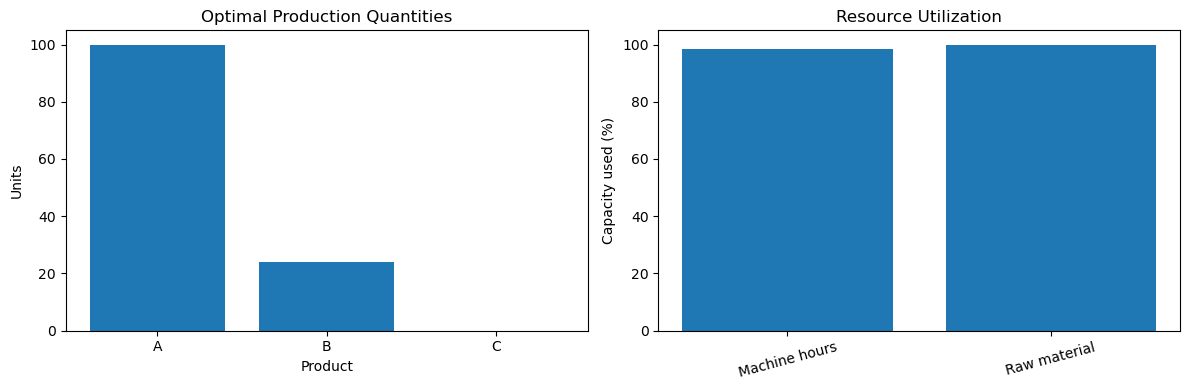

,product,quantity,activated,net_contribution
0,A,100.0,1.0,4080.0
1,B,24.0,1.0,750.0
2,C,0.0,0.0,0.0


,resource,used,capacity,utilization_pct
0,Machine hours,236.0,240.0,98.33
1,Raw material,360.0,360.0,100.00


In [9]:
plan = pd.DataFrame({
    "product": names,
    "quantity": x,
    "activated": y,
    "net_contribution": profit * x - setup * y
})

resource_usage = pd.DataFrame({
    "resource": ["Machine hours", "Raw material"],
    "used": [machine_used, material_used],
    "capacity": [machine_capacity, material_capacity]
})

resource_usage["utilization_pct"] = (
    100 * resource_usage["used"] / resource_usage["capacity"]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(plan["product"], plan["quantity"])
axes[0].set_title("Optimal Production Quantities")
axes[0].set_xlabel("Product")
axes[0].set_ylabel("Units")

axes[1].bar(
    resource_usage["resource"],
    resource_usage["utilization_pct"]
)
axes[1].set_title("Resource Utilization")
axes[1].set_ylabel("Capacity used (%)")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

display(plan.round(2))
display(resource_usage.round(2))

In [10]:
def solve_lp_relaxation(tol=1e-7):
    """
    Solve the LP relaxation by vertex enumeration.

    Decision vector is [x_1, ..., x_n, y_1, ..., y_n].
    This is intended for our small three-product example only.
    """
    num_vars = 2 * n

    # Maximize profit @ x - setup @ y
    objective = np.concatenate([profit, -setup])

    A = []
    b = []

    # Machine and material capacities
    row = np.zeros(num_vars)
    row[:n] = machine
    A.append(row)
    b.append(machine_capacity)

    row = np.zeros(num_vars)
    row[:n] = material
    A.append(row)
    b.append(material_capacity)

    # x_i <= max_i * y_i
    # -x_i + max_i * y_i >= 0
    # Rewritten as x_i - max_i * y_i <= 0
    for i in range(n):
        row = np.zeros(num_vars)
        row[i] = 1
        row[n + i] = -maximum[i]
        A.append(row)
        b.append(0)

    # x_i >= min_i * y_i
    # Rewritten as -x_i + min_i * y_i <= 0
    for i in range(n):
        row = np.zeros(num_vars)
        row[i] = -1
        row[n + i] = minimum[i]
        A.append(row)
        b.append(0)

    # x_i >= 0
    for i in range(n):
        row = np.zeros(num_vars)
        row[i] = -1
        A.append(row)
        b.append(0)

    # 0 <= y_i <= 1
    for i in range(n):
        row = np.zeros(num_vars)
        row[n + i] = -1
        A.append(row)
        b.append(0)

        row = np.zeros(num_vars)
        row[n + i] = 1
        A.append(row)
        b.append(1)

    result = solve_lp_by_vertices(objective, A, b, tol=tol)

    if result["x"] is None:
        raise RuntimeError("LP relaxation did not find a feasible vertex.")

    solution = result["x"]

    return {
        "production": solution[:n],
        "setup": solution[n:],
        "objective": result["objective"],
        "feasible_vertices": result["feasible_vertices"]
    }

In [11]:
lp_solution = solve_lp_relaxation()

milp_profit = best_solution["objective"]
lp_profit = lp_solution["objective"]

absolute_gap = lp_profit - milp_profit
relative_gap = (
    100 * absolute_gap / abs(lp_profit)
    if abs(lp_profit) > 1e-9
    else np.nan
)

print(f"MILP optimal profit:       {milp_profit:.4f}")
print(f"LP relaxation objective:   {lp_profit:.4f}")
print(f"Absolute integrality gap:  {absolute_gap:.4f}")
print(f"Gap as % of LP objective:  {relative_gap:.2f}%")

assert lp_profit >= milp_profit - 1e-6

MILP optimal profit:       4830.0000
LP relaxation objective:   4926.0000
Absolute integrality gap:  96.0000
Gap as % of LP objective:  1.95%


In [12]:
comparison = pd.DataFrame({
    "product": names,
    "MILP_quantity": best_solution["production"],
    "MILP_setup": best_solution["setup"],
    "LP_quantity": lp_solution["production"],
    "LP_setup": lp_solution["setup"]
})

display(comparison.round(4))

,product,MILP_quantity,MILP_setup,LP_quantity,LP_setup
0,A,100.0,1.0,20.0,0.2
1,B,24.0,1.0,120.0,1.0
2,C,0.0,0.0,-0.0,0.0


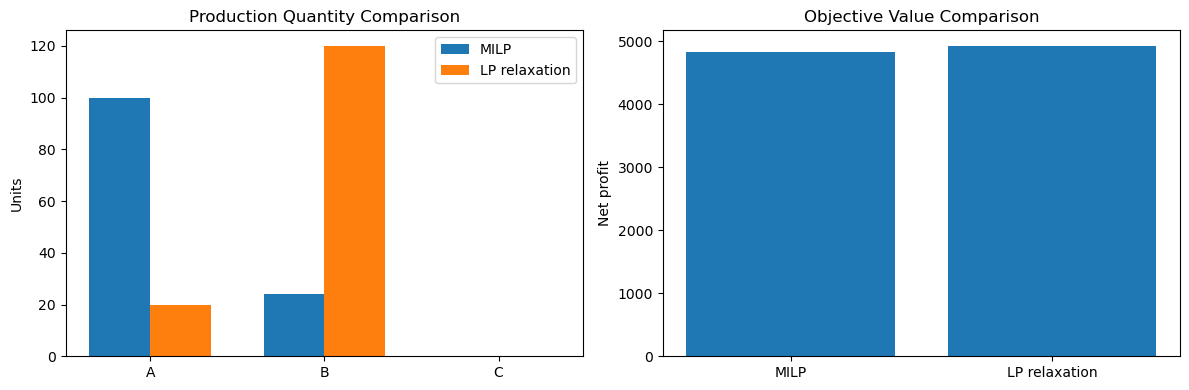

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

x_pos = np.arange(n)
width = 0.35

axes[0].bar(
    x_pos - width / 2,
    best_solution["production"],
    width,
    label="MILP"
)
axes[0].bar(
    x_pos + width / 2,
    lp_solution["production"],
    width,
    label="LP relaxation"
)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(names)
axes[0].set_title("Production Quantity Comparison")
axes[0].set_ylabel("Units")
axes[0].legend()

axes[1].bar(
    ["MILP", "LP relaxation"],
    [milp_profit, lp_profit]
)
axes[1].set_title("Objective Value Comparison")
axes[1].set_ylabel("Net profit")

plt.tight_layout()
plt.show()

In [14]:

def solve_fixed_setup(y, machine_cap=None, material_cap=None):
    if machine_cap is None:
        machine_cap = machine_capacity
    if material_cap is None:
        material_cap = material_capacity

    y = np.asarray(y, dtype=int)

    # Decision variables: production quantities x_i
    A = np.vstack([
        machine,
        material,
        np.eye(n),
        -np.eye(n)
    ])

    b = np.concatenate([
        [machine_cap, material_cap],
        maximum * y,
        -minimum * y
    ])

    result = solve_lp_by_vertices(profit, A, b)

    if result["x"] is None:
        return None

    x = result["x"]
    total_revenue = float(profit @ x)
    total_setup_cost = float(setup @ y)
    net_profit = total_revenue - total_setup_cost

    return {
        "production": x,
        "setup": y,
        "revenue": total_revenue,
        "setup_cost": total_setup_cost,
        "objective": net_profit,
        "machine_used": float(machine @ x),
        "material_used": float(material @ x)
    }


In [15]:

def solve_milp(machine_cap=None, material_cap=None):
    best = None

    for y in product([0, 1], repeat=n):
        candidate = solve_fixed_setup(
            y,
            machine_cap=machine_cap,
            material_cap=material_cap
        )

        if candidate is None:
            continue

        if best is None or candidate["objective"] > best["objective"]:
            best = candidate

    return best


In [16]:

machine_capacities = [160, 200, 240, 280, 320]
machine_results = []

for cap in machine_capacities:
    result = solve_milp(
        machine_cap=cap,
        material_cap=material_capacity
    )

    machine_results.append({
        "machine_capacity": cap,
        "profit": result["objective"],
        "machine_used": result["machine_used"],
        "material_used": result["material_used"],
        "products_active": ", ".join(
            names[i] for i, active in enumerate(result["setup"]) if active
        ),
        **{
            f"quantity_{names[i]}": result["production"][i]
            for i in range(n)
        }
    })

machine_sensitivity = pd.DataFrame(machine_results)
machine_sensitivity


,machine_capacity,profit,machine_used,material_used,products_active,quantity_A,quantity_B,quantity_C
0,160,3643.333333,160.0,266.666667,B,0.0,106.666667,0.0
1,200,4410.000000,200.0,330.000000,"A, B",10.0,120.000000,0.0
2,240,4830.000000,236.0,360.000000,"A, B",100.0,24.000000,0.0
3,280,4830.000000,236.0,360.000000,"A, B",100.0,24.000000,0.0
4,320,4830.000000,236.0,360.000000,"A, B",100.0,24.000000,0.0


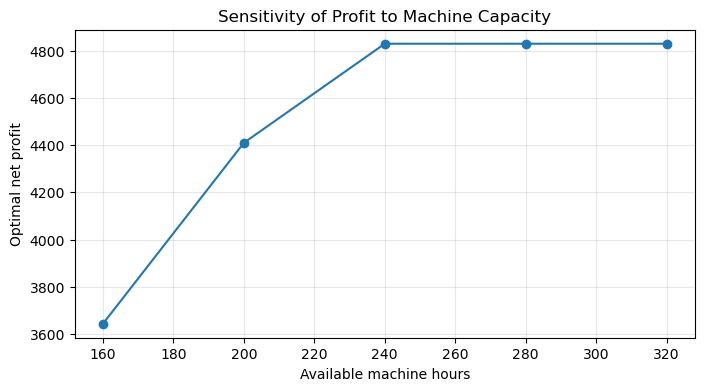

In [17]:

plt.figure(figsize=(8, 4))
plt.plot(
    machine_sensitivity["machine_capacity"],
    machine_sensitivity["profit"],
    marker="o"
)
plt.xlabel("Available machine hours")
plt.ylabel("Optimal net profit")
plt.title("Sensitivity of Profit to Machine Capacity")
plt.grid(True, alpha=0.3)
plt.show()


In [18]:

material_capacities = [240, 300, 360, 420, 480]
material_results = []

for cap in material_capacities:
    result = solve_milp(
        machine_cap=machine_capacity,
        material_cap=cap
    )

    material_results.append({
        "material_capacity": cap,
        "profit": result["objective"],
        "machine_used": result["machine_used"],
        "material_used": result["material_used"],
        "products_active": ", ".join(
            names[i] for i, active in enumerate(result["setup"]) if active
        ),
        **{
            f"quantity_{names[i]}": result["production"][i]
            for i in range(n)
        }
    })

material_sensitivity = pd.DataFrame(material_results)
material_sensitivity


,material_capacity,profit,machine_used,material_used,products_active,quantity_A,quantity_B,quantity_C
0,240,3270.0,144.0,240.0,B,-9.473903e-15,96.0,0.000000e+00
1,300,4110.0,180.0,300.0,B,-1.894781e-14,120.0,1.065814e-14
2,360,4830.0,236.0,360.0,"A, B",1.000000e+02,24.0,0.000000e+00
3,420,5250.0,240.0,390.0,"A, B",3.000000e+01,120.0,0.000000e+00
4,480,5250.0,240.0,390.0,"A, B",3.000000e+01,120.0,0.000000e+00


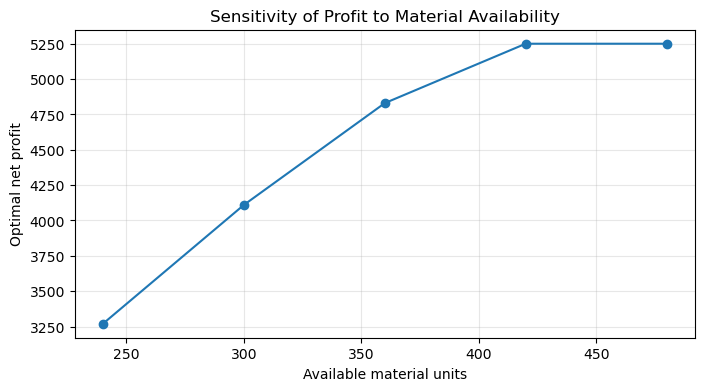

In [19]:

plt.figure(figsize=(8, 4))
plt.plot(
    material_sensitivity["material_capacity"],
    material_sensitivity["profit"],
    marker="o"
)
plt.xlabel("Available material units")
plt.ylabel("Optimal net profit")
plt.title("Sensitivity of Profit to Material Availability")
plt.grid(True, alpha=0.3)
plt.show()


In [20]:

machine_sensitivity["additional_machine_hours"] = (
    machine_sensitivity["machine_capacity"].diff()
)

machine_sensitivity["additional_profit"] = (
    machine_sensitivity["profit"].diff()
)

machine_sensitivity["profit_per_extra_machine_hour"] = (
    machine_sensitivity["additional_profit"]
    / machine_sensitivity["additional_machine_hours"]
)

material_sensitivity["additional_material_units"] = (
    material_sensitivity["material_capacity"].diff()
)

material_sensitivity["additional_profit"] = (
    material_sensitivity["profit"].diff()
)

material_sensitivity["profit_per_extra_material_unit"] = (
    material_sensitivity["additional_profit"]
    / material_sensitivity["additional_material_units"]
)

print("Machine capacity sensitivity:")
display(machine_sensitivity)

print("Material availability sensitivity:")
display(material_sensitivity)


Machine capacity sensitivity:


,machine_capacity,profit,machine_used,material_used,products_active,quantity_A,quantity_B,quantity_C,additional_machine_hours,additional_profit,profit_per_extra_machine_hour
0,160,3643.333333,160.0,266.666667,B,0.0,106.666667,0.0,NaN,NaN,NaN
1,200,4410.000000,200.0,330.000000,"A, B",10.0,120.000000,0.0,40.0,766.666667,19.166667
2,240,4830.000000,236.0,360.000000,"A, B",100.0,24.000000,0.0,40.0,420.000000,10.500000
3,280,4830.000000,236.0,360.000000,"A, B",100.0,24.000000,0.0,40.0,0.000000,0.000000
4,320,4830.000000,236.0,360.000000,"A, B",100.0,24.000000,0.0,40.0,0.000000,0.000000


Material availability sensitivity:


,material_capacity,profit,machine_used,material_used,products_active,quantity_A,quantity_B,quantity_C,additional_material_units,additional_profit,profit_per_extra_material_unit
0,240,3270.0,144.0,240.0,B,-9.473903e-15,96.0,0.000000e+00,NaN,NaN,NaN
1,300,4110.0,180.0,300.0,B,-1.894781e-14,120.0,1.065814e-14,60.0,840.0,14.0
2,360,4830.0,236.0,360.0,"A, B",1.000000e+02,24.0,0.000000e+00,60.0,720.0,12.0
3,420,5250.0,240.0,390.0,"A, B",3.000000e+01,120.0,0.000000e+00,60.0,420.0,7.0
4,480,5250.0,240.0,390.0,"A, B",3.000000e+01,120.0,0.000000e+00,60.0,0.0,0.0


In [21]:

baseline = solve_milp(
    machine_cap=240,
    material_cap=360
)

print("Optimal net profit:", round(baseline["objective"], 2))
print(
    f'Machine utilization: '
    f'{baseline["machine_used"] / 240 * 100:.2f}%'
)
print(
    f'Material utilization: '
    f'{baseline["material_used"] / 360 * 100:.2f}%'
)

baseline_plan = pd.DataFrame({
    "Product": names,
    "Quantity": baseline["production"],
    "Setup selected": baseline["setup"]
})

display(baseline_plan)


Optimal net profit: 4830.0
Machine utilization: 98.33%
Material utilization: 100.00%


,Product,Quantity,Setup selected
0,A,100.0,1
1,B,24.0,1
2,C,0.0,0


In [22]:

display(
    machine_sensitivity[
        [
            "machine_capacity",
            "profit",
            "additional_profit",
            "profit_per_extra_machine_hour"
        ]
    ]
)

display(
    material_sensitivity[
        [
            "material_capacity",
            "profit",
            "additional_profit",
            "profit_per_extra_material_unit"
        ]
    ]
)


,machine_capacity,profit,additional_profit,profit_per_extra_machine_hour
0,160,3643.333333,NaN,NaN
1,200,4410.000000,766.666667,19.166667
2,240,4830.000000,420.000000,10.500000
3,280,4830.000000,0.000000,0.000000
4,320,4830.000000,0.000000,0.000000


,material_capacity,profit,additional_profit,profit_per_extra_material_unit
0,240,3270.0,NaN,NaN
1,300,4110.0,840.0,14.0
2,360,4830.0,720.0,12.0
3,420,5250.0,420.0,7.0
4,480,5250.0,0.0,0.0


In [23]:

def validate_solution(result, machine_cap, material_cap, tol=1e-6):
    x = np.asarray(result["production"], dtype=float)
    y = np.asarray(result["setup"], dtype=int)

    # 1. Production quantities must be nonnegative
    assert np.all(x >= -tol), "Negative production quantity."

    # 2. Binary setup decisions
    assert np.all((y == 0) | (y == 1)), "Setup decisions are not binary."

    # 3. Resource capacities
    assert machine @ x <= machine_cap + tol, "Machine capacity exceeded."
    assert material @ x <= material_cap + tol, "Material capacity exceeded."

    # 4. Setup logic and production bounds
    assert np.all(x <= maximum * y + tol), "Production without setup."
    assert np.all(x >= minimum * y - tol), "Selected product below minimum batch."

    # 5. Objective recomputation, independent of returned objective
    recomputed_profit = float(profit @ x - setup @ y)
    assert abs(recomputed_profit - result["objective"]) <= tol, (
        "Objective calculation mismatch."
    )

    return {
        "feasible": True,
        "recomputed_profit": recomputed_profit,
        "machine_used": float(machine @ x),
        "material_used": float(material @ x)
    }


validation = validate_solution(
    baseline,
    machine_cap=240,
    material_cap=360
)

print(validation)


{'feasible': True, 'recomputed_profit': 4830.0, 'machine_used': 236.0, 'material_used': 360.0}


In [24]:

validation_results = []

for cap in machine_capacities:
    result = solve_milp(
        machine_cap=cap,
        material_cap=material_capacity
    )
    check = validate_solution(result, cap, material_capacity)
    validation_results.append({
        "scenario": "machine",
        "capacity": cap,
        "profit": result["objective"],
        "valid": check["feasible"]
    })

for cap in material_capacities:
    result = solve_milp(
        machine_cap=machine_capacity,
        material_cap=cap
    )
    check = validate_solution(result, machine_capacity, cap)
    validation_results.append({
        "scenario": "material",
        "capacity": cap,
        "profit": result["objective"],
        "valid": check["feasible"]
    })

validation_df = pd.DataFrame(validation_results)
display(validation_df)

assert validation_df["valid"].all()
print("All sensitivity scenarios passed feasibility checks.")


,scenario,capacity,profit,valid
0,machine,160,3643.333333,True
1,machine,200,4410.000000,True
2,machine,240,4830.000000,True
3,machine,280,4830.000000,True
4,machine,320,4830.000000,True
5,material,240,3270.000000,True
6,material,300,4110.000000,True
7,material,360,4830.000000,True
8,material,420,5250.000000,True
9,material,480,5250.000000,True


All sensitivity scenarios passed feasibility checks.


In [25]:

# Product A has a minimum batch of 10.
# This deliberately violates the minimum-batch rule:
invalid_plan = {
    "production": np.array([5.0, 0.0, 0.0]),
    "setup": np.array([1, 0, 0]),
    "objective": 42 * 5 - 120
}

try:
    validate_solution(invalid_plan, 240, 360)
except AssertionError as e:
    print("Invalid plan correctly rejected:", e)
else:
    raise AssertionError("Validation failed to reject an invalid plan.")


Invalid plan correctly rejected: Selected product below minimum batch.


In [26]:

zero_capacity_solution = solve_milp(
    machine_cap=0,
    material_cap=0
)

print("Zero-capacity solution:", zero_capacity_solution)

assert zero_capacity_solution is not None
assert np.allclose(zero_capacity_solution["production"], 0)
assert np.allclose(zero_capacity_solution["setup"], 0)
assert abs(zero_capacity_solution["objective"]) < 1e-6

print("Zero-capacity test passed.")


Zero-capacity solution: {'production': array([0., 0., 0.]), 'setup': array([0, 0, 0]), 'revenue': 0.0, 'setup_cost': 0.0, 'objective': 0.0, 'machine_used': 0.0, 'material_used': 0.0}
Zero-capacity test passed.


In [27]:

insufficient_solution = solve_milp(
    machine_cap=5,
    material_cap=5
)

print("Insufficient-capacity solution:", insufficient_solution)

assert insufficient_solution is not None
assert np.allclose(insufficient_solution["production"], 0)
assert np.allclose(insufficient_solution["setup"], 0)
assert abs(insufficient_solution["objective"]) < 1e-6

print("Insufficient-capacity test passed.")


Insufficient-capacity solution: {'production': array([0., 0., 0.]), 'setup': array([0, 0, 0]), 'revenue': 0.0, 'setup_cost': 0.0, 'objective': 0.0, 'machine_used': 0.0, 'material_used': 0.0}
Insufficient-capacity test passed.
